In [3]:
import pandas as pd

df = pd.read_excel('Online_Retail.xlsx')

df.to_csv('Online_Retail.csv', index=False)

print("Excel file successfully converted to CSV!")

Excel file successfully converted to CSV!


In [5]:
from google.colab import files

files.download('Online_Retail.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
df = pd.read_csv('Online_Retail.csv', encoding='ISO-8859-1')

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")
df = pd.read_csv(
    'Online_Retail.csv',
    encoding='ISO-8859-1'
)

print("Dataset loaded successfully!")
df.head()
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Column names:")
print(df.columns.tolist())
df.info()

Libraries imported successfully!
Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8
Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [15]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [16]:
missing_percentage = (
    df.isnull().sum() / len(df) * 100
).round(2)

print("Missing Value Percentage:")
print(missing_percentage)

Missing Value Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [17]:
missing_report = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().mean() * 100
    ).round(2)
})

missing_report

,Missing Count,Missing Percentage
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


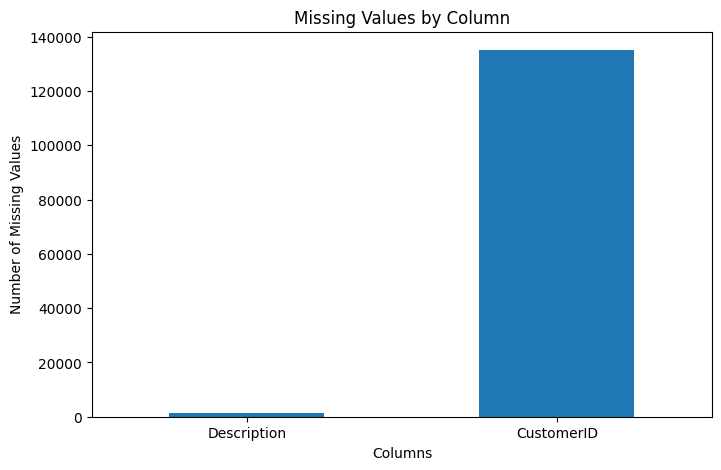

In [18]:
missing_report[missing_report['Missing Count'] > 0]['Missing Count'].plot(
    kind='bar',
    figsize=(8, 5),
    title='Missing Values by Column'
)

plt.ylabel('Number of Missing Values')
plt.xlabel('Columns')
plt.xticks(rotation=0)
plt.show()

In [20]:
cleaned_df = df.copy()

print("Working copy created successfully!")
missing_description = cleaned_df[
    cleaned_df['Description'].isnull()
]

print("Missing description records:")
display(missing_description.head(10))

Working copy created successfully!
Missing description records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom


In [21]:
description_map = (
    cleaned_df.dropna(subset=['Description'])
    .groupby('StockCode')['Description']
    .agg(lambda x: x.mode().iloc[0] if not x.mode().empty else np.nan)
)

cleaned_df['Description'] = (
    cleaned_df['Description'].fillna(
        cleaned_df['StockCode'].map(description_map)
    )
)

In [22]:
cleaned_df['Description'] = (
    cleaned_df['Description'].fillna('Unknown')
)

In [23]:
print(
    "Remaining missing descriptions:",
    cleaned_df['Description'].isnull().sum()
)

Remaining missing descriptions: 0


In [24]:
print("Missing values after treatment:")
print(cleaned_df.isnull().sum())

Missing values after treatment:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


### Missing Value Analysis and Treatment

The initial dataset contained missing values in two columns:

- **Description:** 1,454 missing values (0.27%).
- **CustomerID:** 135,080 missing values (24.93%).

**Cleaning approach:**

1. Missing product descriptions were recovered using the corresponding StockCode wherever a reliable description was available.
2. Any descriptions that could not be recovered were replaced with "Unknown".
3. Missing CustomerIDs were preserved because the actual customer identities could not be determined from the available data.

**Result:** All missing product descriptions were handled while preserving transaction records with unknown customer identities.

Duplicate Record Detection


In [25]:
duplicate_count = cleaned_df.duplicated().sum()

print("Total duplicate records:", duplicate_count)

Total duplicate records: 5268


Duplicate Record Detection and Removal

In [26]:
duplicates = cleaned_df[
    cleaned_df.duplicated(keep=False)
]

print("Total duplicate-related rows:", len(duplicates))

display(duplicates.head(10))

Total duplicate-related rows: 10147


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
548,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom
555,536412,22327,ROUND SNACK BOXES SET OF 4 SKULLS,1,2010-12-01 11:49:00,2.95,17920.0,United Kingdom


In [27]:
print(
    "Duplicate rows to remove:",
    cleaned_df.duplicated().sum()
)

Duplicate rows to remove: 5268


In [28]:
before_removal = len(cleaned_df)

cleaned_df = cleaned_df.drop_duplicates().copy()

after_removal = len(cleaned_df)

removed_rows = before_removal - after_removal

print("Rows before removal:", before_removal)
print("Rows after removal:", after_removal)
print("Duplicate rows removed:", removed_rows)

Rows before removal: 541909
Rows after removal: 536641
Duplicate rows removed: 5268


In [29]:
print(
    "Remaining duplicate records:",
    cleaned_df.duplicated().sum()
)

Remaining duplicate records: 0


### Duplicate Record Detection and Removal

During data quality assessment, 5,268 exact duplicate records were identified.

**Cleaning approach:**

- Used Pandas `duplicated()` to identify duplicate records.
- Inspected duplicate entries before removal.
- Used `drop_duplicates()` to remove exact duplicate rows.
- Verified the dataset again to ensure no exact duplicates remained.

**Result:**

- Original records: 541,909
- Duplicate records removed: 5,268
- Remaining records: 536,641
- Remaining exact duplicates: 0

Removing exact duplicate records helps prevent repeated transaction entries from affecting subsequent analysis.

In [30]:
print("Current Data Types:")
print(cleaned_df.dtypes)

Current Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [31]:
cleaned_df['InvoiceDate'] = pd.to_datetime(
    cleaned_df['InvoiceDate'],
    errors='coerce'
)

print(cleaned_df['InvoiceDate'].dtype)

datetime64[ns]


In [32]:
cleaned_df['CustomerID'] = (
    cleaned_df['CustomerID']
    .astype('Int64')
    .astype('string')
)

In [33]:
cleaned_df['InvoiceNo'] = (
    cleaned_df['InvoiceNo'].astype('string')
)

cleaned_df['StockCode'] = (
    cleaned_df['StockCode'].astype('string')
)

In [34]:
print("Updated Data Types:")
print(cleaned_df.dtypes)

cleaned_df.info()

Updated Data Types:
InvoiceNo      string[python]
StockCode      string[python]
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID     string[python]
Country                object
dtype: object
<class 'pandas.core.frame.DataFrame'>
Index: 536641 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    536641 non-null  string        
 1   StockCode    536641 non-null  string        
 2   Description  536641 non-null  object        
 3   Quantity     536641 non-null  int64         
 4   InvoiceDate  536641 non-null  datetime64[ns]
 5   UnitPrice    536641 non-null  float64       
 6   CustomerID   401604 non-null  string        
 7   Country      536641 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(2), string(3)
memory usage: 36.8+ MB


Data Type Correction
- Converted InvoiceDate from object to datetime.
- Converted CustomerID from float to string while preserving missing values.
- Converted InvoiceNo and StockCode into strings because they represent identifiers.
- Verified the updated data types using Pandas.


In [35]:
cleaned_df.dtypes

,0
InvoiceNo,string[python]
StockCode,string[python]
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,string[python]
Country,object


In [36]:
negative_quantity = cleaned_df[
    cleaned_df['Quantity'] < 0
]

print("Negative quantity records:",
      len(negative_quantity))

display(negative_quantity.head(10))

Negative quantity records: 10587


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897,United Kingdom


In [37]:
zero_quantity = cleaned_df[
    cleaned_df['Quantity'] == 0
]

print("Zero quantity records:", len(zero_quantity))

Zero quantity records: 0


In [38]:
negative_price = cleaned_df[
    cleaned_df['UnitPrice'] < 0
]

print("Negative unit price records:",
      len(negative_price))

display(negative_price.head(10))

Negative unit price records: 2


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom


In [39]:
zero_price = cleaned_df[
    cleaned_df['UnitPrice'] == 0
]

print("Zero unit price records:",
      len(zero_price))


Zero unit price records: 2510


In [40]:
cancelled_invoices = cleaned_df[
    cleaned_df['InvoiceNo'].str.startswith(
        'C', na=False
    )
]

print("Cancelled invoice records:",
      len(cancelled_invoices))

display(cancelled_invoices.head(10))

Cancelled invoice records: 9251


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897,United Kingdom


Data Type Correction

The dataset initially contained incorrect or unsuitable data types in certain columns. The following changes were made:
- Converted InvoiceDate from object to datetime.
- Converted CustomerID from float to string.
- Converted InvoiceNo and StockCode from object to string.
- Verified the updated data types using Pandas.
The conversions improve data consistency and make the dataset suitable for further analysis


In [41]:
print("Negative quantities:",
      (cleaned_df['Quantity'] < 0).sum())

print("Zero quantities:",
      (cleaned_df['Quantity'] == 0).sum())

print("Negative unit prices:",
      (cleaned_df['UnitPrice'] < 0).sum())

print("Zero unit prices:",
      (cleaned_df['UnitPrice'] == 0).sum())

print("Cancelled invoices:",
      cleaned_df['InvoiceNo'].str.startswith('C', na=False).sum())

Negative quantities: 10587
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2510
Cancelled invoices: 9251


In [42]:
cleaned_df['Description'] = (
    cleaned_df['Description']
    .astype('string')
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
)

cleaned_df['Country'] = (
    cleaned_df['Country']
    .astype('string')
    .str.strip()
)

In [43]:
cleaned_df['TransactionType'] = np.select(
    [
        cleaned_df['InvoiceNo'].str.startswith('C', na=False),
        cleaned_df['Quantity'] < 0,
        cleaned_df['UnitPrice'] <= 0
    ],
    [
        'Cancellation',
        'Return',
        'Zero or Negative Price'
    ],
    default='Sale'
)

In [44]:
print(cleaned_df['TransactionType'].value_counts())

TransactionType
Sale                      524878
Cancellation                9251
Return                      1336
Zero or Negative Price      1176
Name: count, dtype: int64


In [45]:
negative_price_records = cleaned_df[
    cleaned_df['UnitPrice'] < 0
]

display(negative_price_records)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,<NA>,United Kingdom,Zero or Negative Price
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,<NA>,United Kingdom,Zero or Negative Price


In [46]:
zero_price_records = cleaned_df[
    cleaned_df['UnitPrice'] == 0
]

print("Zero price records:",
      len(zero_price_records))

display(zero_price_records.head(10))

Zero price records: 2510


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType
622,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom,Zero or Negative Price
1970,536545,21134,Unknown,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom,Zero or Negative Price
1971,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom,Zero or Negative Price
1972,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom,Zero or Negative Price
1987,536549,85226A,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero or Negative Price
1988,536550,85044,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero or Negative Price
2024,536552,20950,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero or Negative Price
2025,536553,37461,FUNKY MONKEY MUG,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom,Zero or Negative Price
2026,536554,84670,Unknown,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom,Zero or Negative Price
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom,Return


In [53]:
cleaned_df['TransactionType'] = np.select(
    [
        cleaned_df['Description'].str.contains(
            'adjust bad debt', case=False, na=False
        ),
        cleaned_df['InvoiceNo'].str.startswith(
            'C', na=False
        ),
        cleaned_df['Quantity'] < 0,
        cleaned_df['UnitPrice'] < 0,
        cleaned_df['UnitPrice'] == 0
    ],
    [
        'Bad Debt Adjustment',
        'Cancellation',
        'Return',
        'Negative Price',
        'Zero Price'
    ],
    default='Sale'
)

In [54]:
cleaned_df['DataQualityFlag'] = np.select(
    [
        cleaned_df['TransactionType'] == 'Bad Debt Adjustment',
        cleaned_df['TransactionType'] == 'Zero Price',
        cleaned_df['TransactionType'] == 'Negative Price',
        cleaned_df['Description'] == 'Unknown'
    ],
    [
        'Accounting Adjustment',
        'Zero Price - Review',
        'Negative Price - Review',
        'Unknown Description'
    ],
    default='Normal'
)

In [55]:
display(
    cleaned_df[
        ['InvoiceNo', 'Description', 'Quantity',
         'UnitPrice', 'TransactionType', 'DataQualityFlag']
    ].head(15)
)

,InvoiceNo,Description,Quantity,UnitPrice,TransactionType,DataQualityFlag
0,536365,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,Sale,Normal
1,536365,WHITE METAL LANTERN,6,3.39,Sale,Normal
2,536365,CREAM CUPID HEARTS COAT HANGER,8,2.75,Sale,Normal
3,536365,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,Sale,Normal
4,536365,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,Sale,Normal
5,536365,SET 7 BABUSHKA NESTING BOXES,2,7.65,Sale,Normal
6,536365,GLASS STAR FROSTED T-LIGHT HOLDER,6,4.25,Sale,Normal
7,536366,HAND WARMER UNION JACK,6,1.85,Sale,Normal
8,536366,HAND WARMER RED POLKA DOT,6,1.85,Sale,Normal
9,536367,ASSORTED COLOUR BIRD ORNAMENT,32,1.69,Sale,Normal


In [56]:
zero_price_records = cleaned_df[
    cleaned_df['UnitPrice'] == 0
]

display(zero_price_records.head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TransactionType,TotalAmount,DataQualityFlag
622,536414,22139,RETROSPOT TEA SET CERAMIC 11 PC,56,2010-12-01 11:52:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
1970,536545,21134,Unknown,1,2010-12-01 14:32:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
1971,536546,22145,CHRISTMAS CRAFT HEART STOCKING,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
1972,536547,37509,NEW ENGLAND MUG W GIFT BOX,1,2010-12-01 14:33:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
1987,536549,85226A,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
1988,536550,85044,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
2024,536552,20950,Unknown,1,2010-12-01 14:34:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
2025,536553,37461,FUNKY MONKEY MUG,3,2010-12-01 14:35:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
2026,536554,84670,Unknown,23,2010-12-01 14:35:00,0.0,<NA>,United Kingdom,Zero Price,0.0,Zero Price - Review
2406,536589,21777,RECIPE BOX WITH METAL HEART,-10,2010-12-01 16:50:00,0.0,<NA>,United Kingdom,Return,-0.0,Normal


In [57]:
transaction_summary = (
    cleaned_df['TransactionType']
    .value_counts()
    .reset_index()
)

transaction_summary.columns = [
    'Transaction Type',
    'Record Count'
]

display(transaction_summary)

,Transaction Type,Record Count
0,Sale,524877
1,Cancellation,9251
2,Return,1336
3,Zero Price,1174
4,Bad Debt Adjustment,3


In [58]:
display(
    cleaned_df['DataQualityFlag'].value_counts()
)

,count
DataQualityFlag,
Normal,535367
Zero Price - Review,1174
Unknown Description,97
Accounting Adjustment,3


In [59]:
cleaned_df['TotalAmount'] = (
    cleaned_df['Quantity'] *
    cleaned_df['UnitPrice']
).round(2)

In [60]:
display(
    cleaned_df[
        ['InvoiceNo', 'Quantity', 'UnitPrice',
         'TotalAmount', 'TransactionType']
    ].head(10)
)

,InvoiceNo,Quantity,UnitPrice,TotalAmount,TransactionType
0,536365,6,2.55,15.30,Sale
1,536365,6,3.39,20.34,Sale
2,536365,8,2.75,22.00,Sale
3,536365,6,3.39,20.34,Sale
4,536365,6,3.39,20.34,Sale
5,536365,2,7.65,15.30,Sale
6,536365,6,4.25,25.50,Sale
7,536366,6,1.85,11.10,Sale
8,536366,6,1.85,11.10,Sale
9,536367,32,1.69,54.08,Sale


### Identification and Treatment of Inconsistent Values

The dataset was examined for unusual numerical values and cancelled transactions.

**Findings:**
- Negative quantities: 10,587
- Zero quantities: 0
- Negative unit prices: 2
- Zero unit prices: 2,510
- Cancelled invoice records: 9,251

**Cleaning decisions:**

1. Negative quantities were preserved because they may represent returned or cancelled items.
2. Cancelled invoices were identified using invoice numbers beginning with 'C'.
3. Zero and negative unit prices were investigated rather than automatically deleted.
4. A TransactionType column was created to distinguish sales, returns, cancellations and unusual price records.
5. A TotalAmount column was calculated using Quantity × UnitPrice.

These steps help retain meaningful transaction information while improving the interpretability of the dataset.


In [61]:
print("Missing values:")
print(cleaned_df.isnull().sum())

Missing values:
InvoiceNo               0
StockCode               0
Description             0
Quantity                0
InvoiceDate             0
UnitPrice               0
CustomerID         135037
Country                 0
TransactionType         0
TotalAmount             0
DataQualityFlag         0
dtype: int64


In [62]:
print("Duplicate records:",
      cleaned_df.duplicated().sum())

Duplicate records: 0


In [63]:
print(cleaned_df.dtypes)

InvoiceNo          string[python]
StockCode          string[python]
Description        string[python]
Quantity                    int64
InvoiceDate        datetime64[ns]
UnitPrice                 float64
CustomerID         string[python]
Country            string[python]
TransactionType            object
TotalAmount               float64
DataQualityFlag            object
dtype: object


In [64]:
print(cleaned_df['TransactionType'].value_counts())

TransactionType
Sale                   524877
Cancellation             9251
Return                   1336
Zero Price               1174
Bad Debt Adjustment         3
Name: count, dtype: int64


In [65]:
print("Final rows:", cleaned_df.shape[0])
print("Final columns:", cleaned_df.shape[1])

Final rows: 536641
Final columns: 11


In [66]:
cleaned_df['TotalAmount'] = (
    cleaned_df['Quantity'] * cleaned_df['UnitPrice']
).round(2)

In [67]:
cleaned_df['TotalAmount'] = (
    cleaned_df['Quantity'] * cleaned_df['UnitPrice']
).round(2)

In [69]:
import os

print(os.listdir('/content'))

['.config', 'Online_Retail.xlsx', 'Online_Retail.csv', '.ipynb_checkpoints', 'sample_data']


In [70]:
cleaned_df.to_csv(
    '/content/cleaned_online_retail.csv',
    index=False
)

print("Cleaned dataset exported successfully!")

Cleaned dataset exported successfully!


In [71]:
import os

print(os.listdir('/content'))

['.config', 'cleaned_online_retail.csv', 'Online_Retail.xlsx', 'Online_Retail.csv', '.ipynb_checkpoints', 'sample_data']


In [72]:
from google.colab import files

files.download('/content/cleaned_online_retail.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>